In [52]:
import matplotlib as mpl
import seaborn as sns
import importlib

# Seaborn theme
sns.set_theme(
    style="ticks",        # "white", "whitegrid", "ticks", "darkgrid"
    context="paper",       # notebook, paper, talk, poster
    palette="deep"
)

# Your publication formatting
mpl.rcParams.update({

    # Fonts
    "font.family": "Arial",
    "font.size": 14,

    # Figure titles
    "figure.titlesize": 34,
    "figure.titleweight": "bold",

    # Axes titles/labels
    "axes.titlesize": 14,
    "axes.labelsize": 14,

    # Tick labels
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,

    # Legend
    "legend.fontsize": 16,
    "legend.title_fontsize": 18,

    # Lines & markers
    "lines.linewidth": 3,
    "lines.markersize": 8,

    # Axes
    "axes.linewidth": 2,

    # Ticks
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "xtick.minor.width": 1.5,
    "ytick.minor.width": 1.5,

    # Grid
    "grid.linewidth": 1,
    "grid.alpha": 0.3,

    # Export
    "figure.dpi": 150,
    "savefig.dpi": 600,

    # Editable vector graphics
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

# Escape-assay parameter-sweep analysis

This notebook discovers self-contained escape-assay replicate folders, recreates individual 3D receptor-interpolated maps, and compares residence time and rebinding across sweep parameters. It treats each receptor-layout replicate as the experimental unit and retains censoring information throughout.

In [53]:
from pathlib import Path
import importlib
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "utils").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "utils").is_dir():
    raise RuntimeError("Could not locate the SensorModeling repository root.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import utils.escape_assay_viz as escape_viz
importlib.reload(escape_viz)

from utils.escape_assay_viz import (
    load_escape_assay_run,
    plot_kaplan_meier_curves,
    plot_surface_metric_3d,
    plot_surface_metric_xy,
)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", None)

## 1. Select and discover a sweep

Set `SWEEP_ROOT` to the downloaded curvature- or receptor-density-sweep folder. The recursive search expects one `manifest.json` inside every completed replicate folder.

In [54]:
# Change this path to any escape-assay folder copied back from the cluster.
# Bowl sweeps, cylindrical-sheet sweeps, and fixed sinusoidal replicates are supported.
SWEEP_ROOT = "/Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260923_escape_assay_cylindrical_sheet_curvature_sweep"

# Accept either a pathlib.Path or a quoted string, including paths with spaces.
SWEEP_ROOT = Path(SWEEP_ROOT).expanduser().resolve()

# Convenient fallback so the notebook can also inspect the example run.
if not list(SWEEP_ROOT.glob("**/manifest.json")):
    example_root = PROJECT_ROOT / "data/escape_assay/spherical_bowl"
    if (example_root / "manifest.json").exists():
        print(f"No sweep bundles found under {SWEEP_ROOT}; using {example_root}.")
        SWEEP_ROOT = example_root

manifest_paths = sorted(SWEEP_ROOT.glob("**/manifest.json"))
if not manifest_paths:
    raise FileNotFoundError(
        f"No manifest.json files found below {SWEEP_ROOT.resolve()}"
    )
print(f"Found {len(manifest_paths):,} completed replicate bundle(s).")

Found 35 completed replicate bundle(s).


In [55]:
def index_run(manifest_path):
    with manifest_path.open("r", encoding="utf-8") as stream:
        manifest = json.load(stream)
    run = manifest.get("run_metadata", {})
    parameter = run.get("sweep_parameter") or "condition"
    value = run.get("sweep_value", 0.0)
    replicate = run.get("replicate", 1)
    params = manifest.get("params", {})
    directory = manifest_path.parent
    return {
        "run_directory": directory,
        "relative_directory": str(directory.relative_to(SWEEP_ROOT)),
        "sweep_parameter": parameter,
        "protocol": run.get("protocol", "unknown"),
        "geometry_type": run.get("geometry_type", manifest.get("geometry_name", "unknown")),
        "sweep_value": float(value) if value is not None else np.nan,
        "replicate": int(replicate),
        "n_receptors": int(manifest.get("n_receptors", 0)),
        "n_trajectories": int(manifest.get("n_trajectories", 0)),
        "geometry_name": manifest.get("geometry_name", "unknown"),
        "k_on_M_inv_s": float(params.get("k_on_M_inv_s", np.nan)),
        "k_off_s": float(params.get("k_off_s", np.nan)),
        "KD_M": (
            float(params.get("k_off_s")) / float(params.get("k_on_M_inv_s"))
            if float(params.get("k_on_M_inv_s", 0.0)) > 0 else np.nan
        ),
    }

run_index = pd.DataFrame([index_run(path) for path in manifest_paths])
parameter_names = run_index["sweep_parameter"].dropna().unique()
SWEEP_PARAMETER = parameter_names[0] if len(parameter_names) else "condition"
if SWEEP_PARAMETER == "radius_m":
    # A null radius denotes the exact planar limit: curvature = 0.
    run_index["plot_value"] = np.where(
        run_index["sweep_value"].isna(),
        0.0,
        1e-9 / run_index["sweep_value"],
    )
    PLOT_PARAMETER = "Concave curvature (nm$^{-1}$)"
elif SWEEP_PARAMETER == "receptor_density_m2":
    run_index["plot_value"] = run_index["sweep_value"] / 1e16
    PLOT_PARAMETER = "Receptor density ($10^{16}$ m$^{-2}$)"
elif SWEEP_PARAMETER == "geometry_replicate":
    # Every replicate uses the same sinusoidal geometry.
    run_index["plot_value"] = 0.0
    PLOT_PARAMETER = "Fixed sinusoidal geometry"
elif SWEEP_PARAMETER == "kinetic_scale":
    run_index["plot_value"] = run_index["sweep_value"]
    PLOT_PARAMETER = r"Kinetic rate multiplier at constant $K_D$"
else:
    run_index["plot_value"] = run_index["sweep_value"]
    PLOT_PARAMETER = SWEEP_PARAMETER
run_index.sort_values(["plot_value", "replicate"], inplace=True, ignore_index=True)
run_index

,run_directory,relative_directory,sweep_parameter,protocol,geometry_type,sweep_value,replicate,n_receptors,n_trajectories,geometry_name,k_on_M_inv_s,k_off_s,KD_M,plot_value
0,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,planar/replicate_001,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,NaN,1,500,10000,cylindrically_curved_sheet_planar,100000000.0,200.0,0.000002,0.000000
1,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,planar/replicate_002,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,NaN,2,500,10000,cylindrically_curved_sheet_planar,100000000.0,200.0,0.000002,0.000000
2,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,planar/replicate_003,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,NaN,3,500,10000,cylindrically_curved_sheet_planar,100000000.0,200.0,0.000002,0.000000
3,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,planar/replicate_004,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,NaN,4,500,10000,cylindrically_curved_sheet_planar,100000000.0,200.0,0.000002,0.000000
4,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,planar/replicate_005,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,NaN,5,500,10000,cylindrically_curved_sheet_planar,100000000.0,200.0,0.000002,0.000000
5,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,radius_m_2e-07/replicate_001,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,2.000000e-07,1,570,11400,cylindrically_curved_sheet_radius_m_2e-07,100000000.0,200.0,0.000002,0.005000
6,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,radius_m_2e-07/replicate_002,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,2.000000e-07,2,570,11400,cylindrically_curved_sheet_radius_m_2e-07,100000000.0,200.0,0.000002,0.005000
7,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,radius_m_2e-07/replicate_003,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,2.000000e-07,3,570,11400,cylindrically_curved_sheet_radius_m_2e-07,100000000.0,200.0,0.000002,0.005000
8,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,radius_m_2e-07/replicate_004,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,2.000000e-07,4,570,11400,cylindrically_curved_sheet_radius_m_2e-07,100000000.0,200.0,0.000002,0.005000
9,/Users/rynon/Library/CloudStorage/OneDrive-Nor...,radius_m_2e-07/replicate_005,radius_m,escape_assay_cylindrical_sheet_curvature_sweep,cylindrically_curved_sheet,2.000000e-07,5,570,11400,cylindrically_curved_sheet_radius_m_2e-07,100000000.0,200.0,0.000002,0.005000


## 2. Inspect one replicate in 3D and from overhead

Select any row from `run_index`. The first figure shows the requested metrics as adjacent 3D panels. The second figure projects the upward-facing surface onto the x–y plane, corresponding to a direct overhead view. Change `MAP_METRICS` to numeric columns in `archive.receptor_summary`.

Selected: /Users/rynon/Library/CloudStorage/OneDrive-NorthwesternUniversity/PhD/Data/Agent-based simulations/260923_escape_assay_cylindrical_sheet_curvature_sweep/radius_m_6e-08/replicate_001


,location_id,n_trials,n_escaped,escape_probability,median_observation_time_s,mean_observation_time_s,median_escape_time_s,median_rebindings,mean_rebindings,probability_any_rebinding,median_self_rebindings,median_cross_rebindings,mean_bound_time_s,source_face_id,release_x_m,release_y_m,release_z_m,receptor_id,surface_x_m,surface_y_m,surface_z_m
count,770.000000,770.0,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,770.000000,7.700000e+02,7.700000e+02,7.700000e+02,770.000000,7.700000e+02,7.700000e+02,7.700000e+02
mean,384.500000,20.0,19.998701,0.999935,0.066075,0.095069,0.066070,13.340909,19.015909,0.948117,0.807792,11.885714,0.094976,7350.529870,4.850390e-08,5.145844e-08,3.448831e-08,384.500000,4.849935e-08,5.145844e-08,3.418117e-08
std,222.424144,0.0,0.036037,0.001802,0.023756,0.023845,0.023751,4.579064,4.653074,0.053787,0.532498,4.627607,0.023828,4469.912759,3.238962e-08,2.904633e-08,7.987343e-09,222.424144,3.259501e-08,2.904633e-08,8.055802e-09
min,0.000000,20.0,19.000000,0.950000,0.013088,0.030523,0.013088,2.500000,6.700000,0.750000,0.000000,1.000000,0.030475,22.000000,0.000000e+00,0.000000e+00,2.400000e-08,0.000000,0.000000e+00,0.000000e+00,2.350000e-08
25%,192.250000,20.0,20.000000,1.000000,0.049009,0.078613,0.049009,10.000000,15.650000,0.900000,0.500000,8.500000,0.078527,3556.250000,1.800000e-08,2.625000e-08,2.700000e-08,192.250000,1.750000e-08,2.625000e-08,2.650000e-08
50%,384.500000,20.0,20.000000,1.000000,0.064482,0.093272,0.064482,13.000000,18.650000,0.950000,1.000000,11.500000,0.093184,7010.000000,5.000000e-08,5.200000e-08,3.300000e-08,384.500000,5.000000e-08,5.200000e-08,3.300000e-08
75%,576.750000,20.0,20.000000,1.000000,0.079863,0.109995,0.079863,16.000000,22.000000,1.000000,1.000000,14.500000,0.109884,11295.750000,8.000000e-08,7.700000e-08,4.100000e-08,576.750000,8.000000e-08,7.700000e-08,4.100000e-08
max,769.000000,20.0,20.000000,1.000000,0.175074,0.186916,0.175074,33.000000,36.250000,1.000000,3.000000,31.000000,0.186766,15393.000000,9.900000e-08,9.900000e-08,5.100000e-08,769.000000,9.900000e-08,9.900000e-08,5.050000e-08


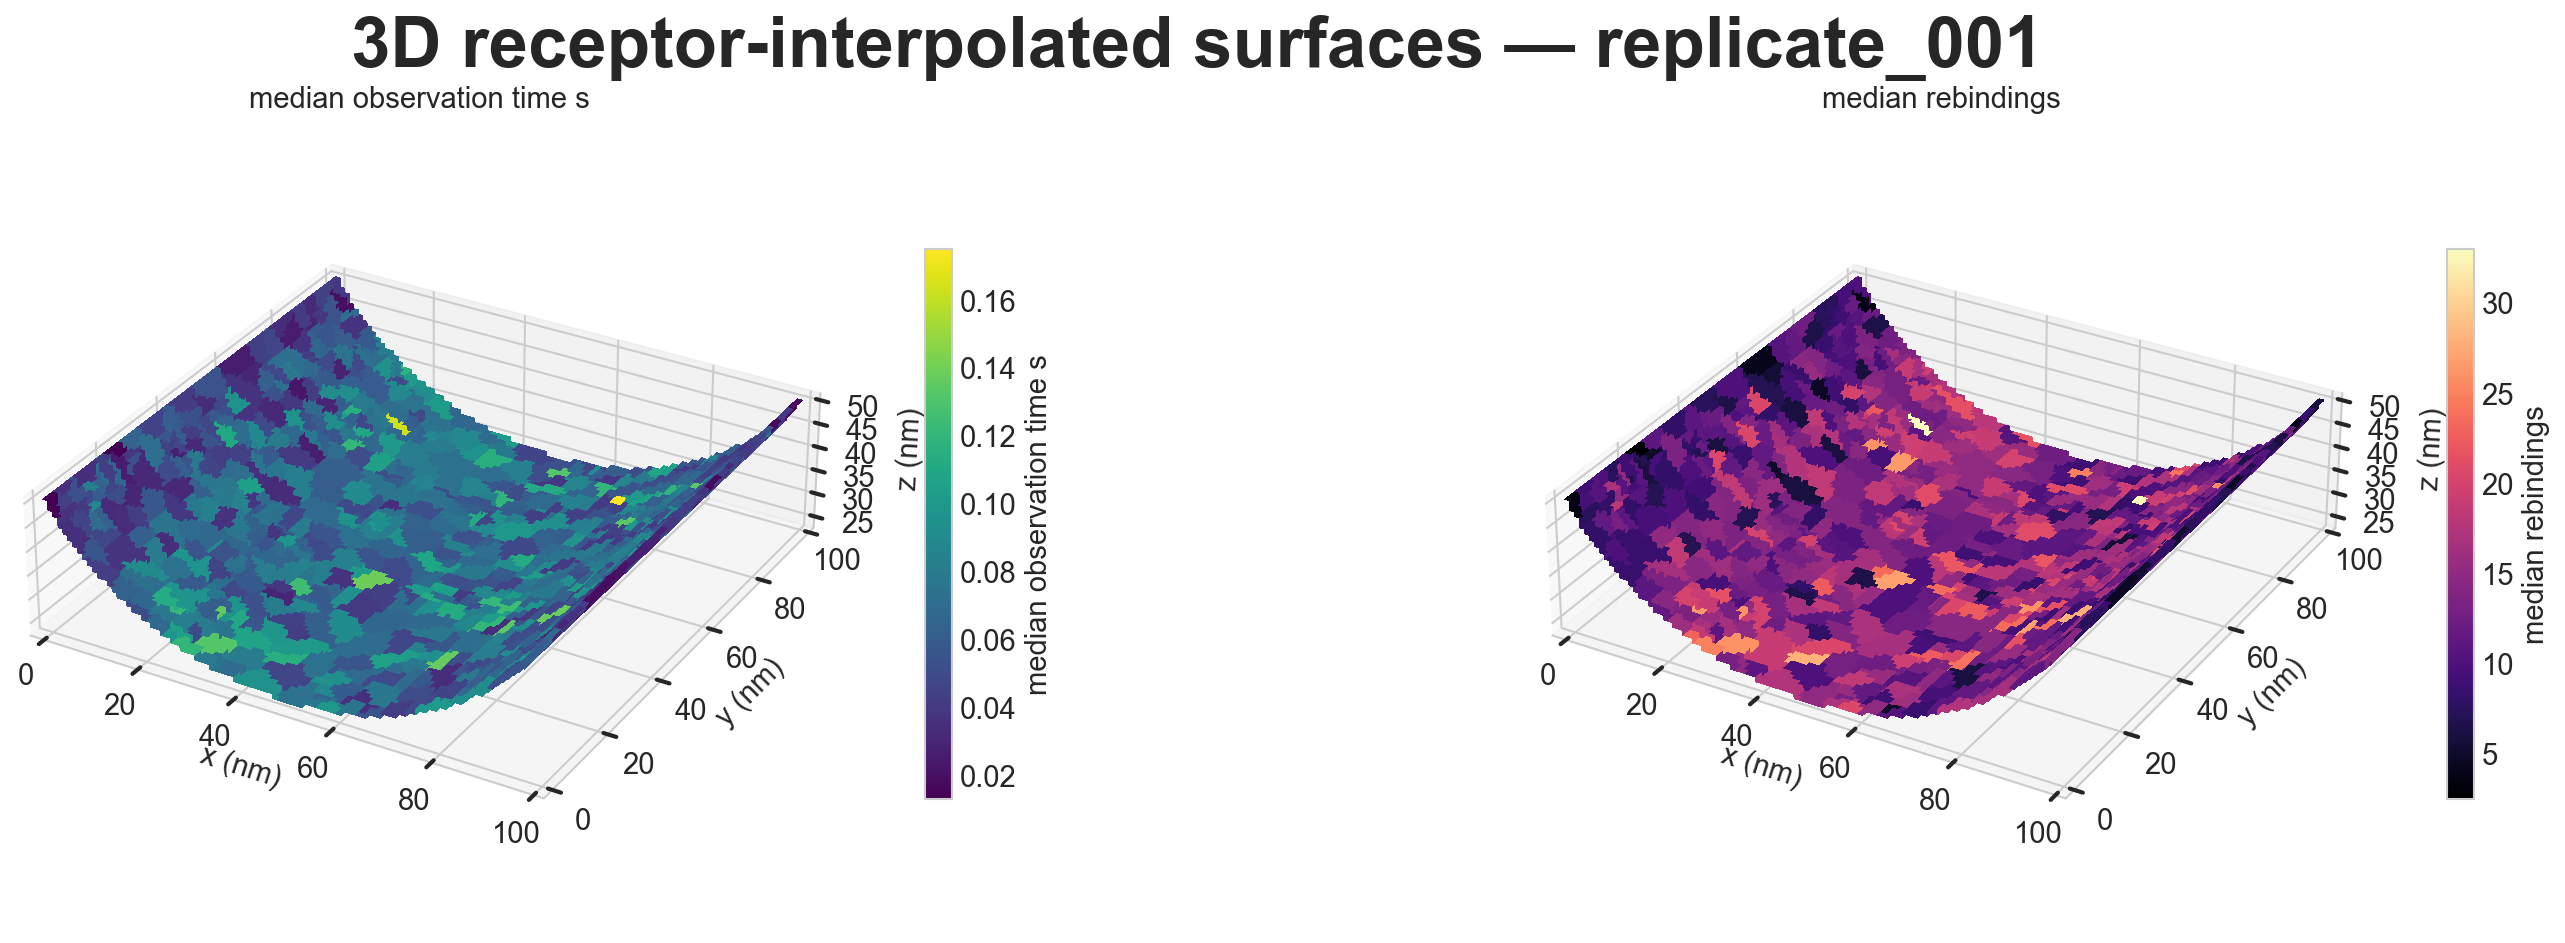

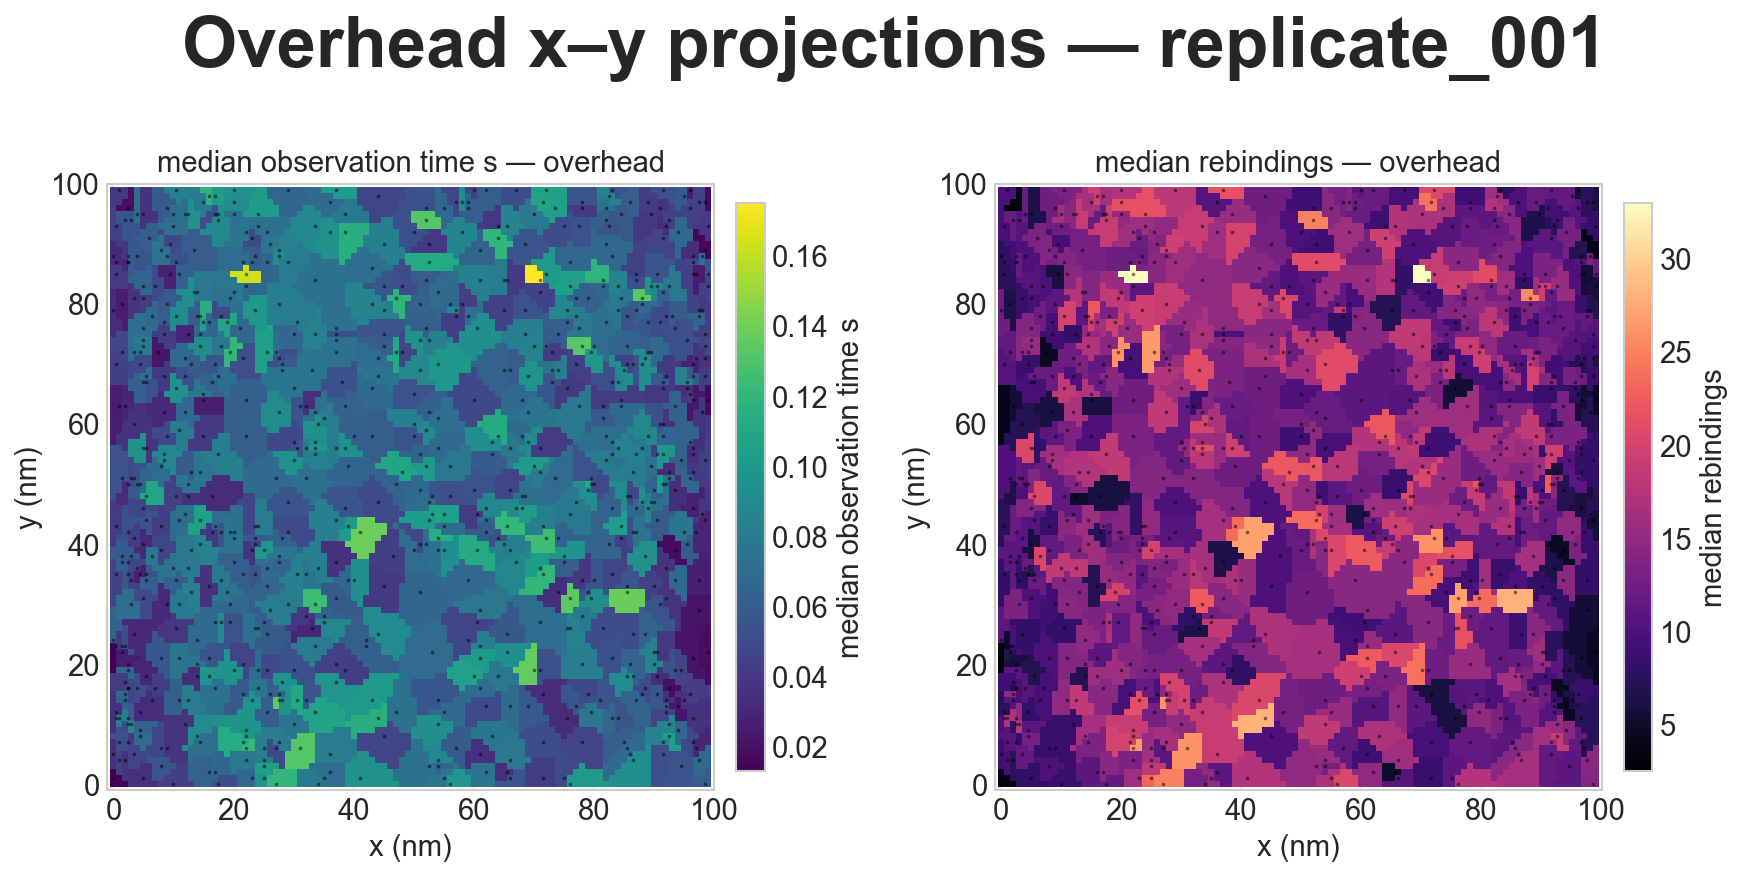

In [74]:
RUN_INDEX = 20
MAP_METRICS = ["median_observation_time_s", "median_rebindings"]

selected_directory = Path(run_index.loc[RUN_INDEX, "run_directory"])
archive = load_escape_assay_run(selected_directory)
print(f"Selected: {selected_directory}")
display(archive.receptor_summary.describe())

metric_cmaps = {
    "median_observation_time_s": "viridis",
    "median_rebindings": "magma",
}

fig_3d = plt.figure(figsize=(12 * len(MAP_METRICS), 7))
surface_maps_3d = {}
for panel, metric in enumerate(MAP_METRICS, start=1):
    ax = fig_3d.add_subplot(1, len(MAP_METRICS), panel, projection="3d")
    _, ax, interpolated = plot_surface_metric_3d(
        archive.geometry,
        archive.receptor_summary,
        metric,
        a_m=archive.params.a_m,
        cmap=metric_cmaps.get(metric, "viridis"),
        show_receptors=False,
        ax=ax,
    )
    ax.view_init(elev=30, azim=-60)
    ax.set_title(metric.replace("_", " "))
    surface_maps_3d[metric] = interpolated
fig_3d.suptitle(f"3D receptor-interpolated surfaces — {selected_directory.name}", y=0.98)
plt.show()

fig_xy, axes_xy = plt.subplots(1, len(MAP_METRICS), figsize=(7 * len(MAP_METRICS), 6), squeeze=False)
surface_maps_xy = {}
for ax, metric in zip(axes_xy.flat, MAP_METRICS):
    _, ax, projected = plot_surface_metric_xy(
        archive.geometry,
        archive.receptor_summary,
        metric,
        a_m=archive.params.a_m,
        cmap=metric_cmaps.get(metric, "viridis"),
        show_receptors=True,
        receptor_size=3,
        ax=ax,
    )
    surface_maps_xy[metric] = projected
fig_xy.suptitle(f"Overhead x–y projections — {selected_directory.name}", y=1.02)
plt.show()

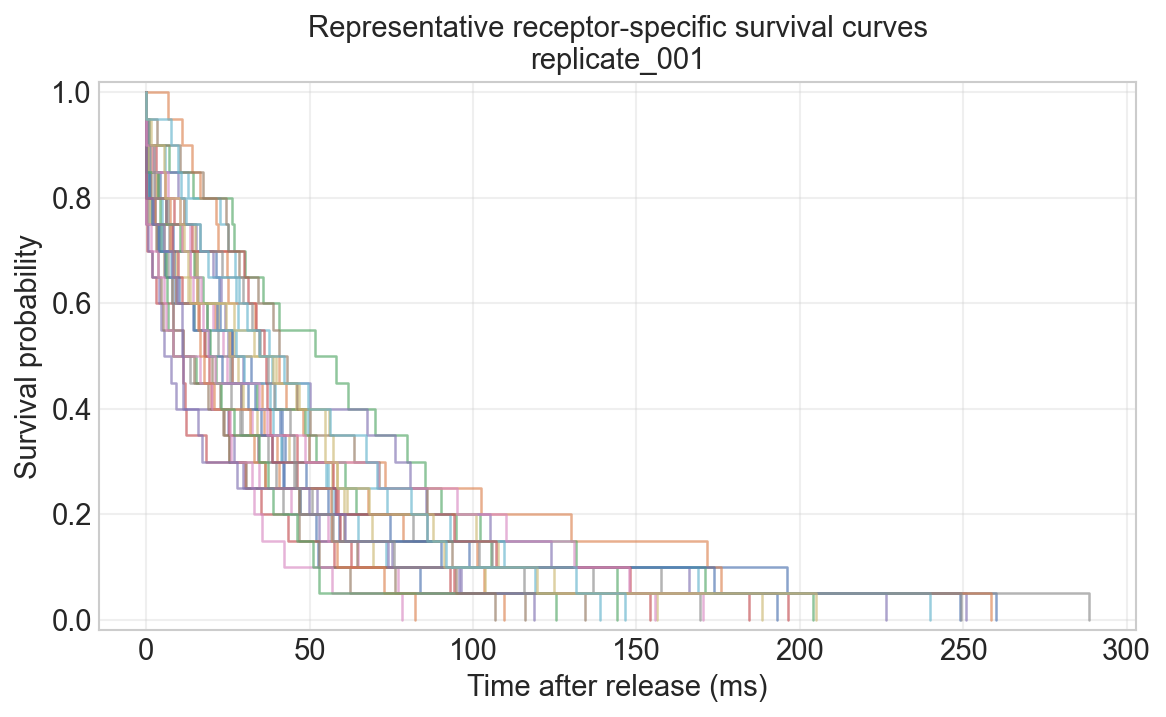

In [57]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_kaplan_meier_curves(archive.survival, max_curves=30, ax=ax)
ax.set_title(f"Representative receptor-specific survival curves\n{selected_directory.name}")
plt.tight_layout()
plt.show()

## 3. Assemble replicate- and trajectory-level sweep tables

The restricted mean residence time (RMST) up to the assay horizon equals the mean observed time because every unescaped trajectory is censored at that common horizon. RMST is preferable to the mean escape time among escaped molecules, which is biased downward when censoring is substantial.

In [58]:
trajectory_frames = []
receptor_frames = []
run_rows = []

for row in run_index.itertuples(index=False):
    current = load_escape_assay_run(row.run_directory)
    trajectories = current.trajectories.copy()
    trajectories["sweep_parameter"] = row.sweep_parameter
    trajectories["sweep_value"] = row.sweep_value
    trajectories["replicate"] = row.replicate
    trajectories["plot_value"] = row.plot_value
    trajectories["geometry_type"] = row.geometry_type
    trajectories["run_directory"] = str(row.run_directory)
    trajectories["free_time_s"] = (
        trajectories["observation_time_s"] - trajectories["total_bound_time_s"]
    ).clip(lower=0)
    trajectory_frames.append(trajectories)

    receptors = current.receptor_summary.copy()
    receptors["sweep_value"] = row.sweep_value
    receptors["replicate"] = row.replicate
    receptors["plot_value"] = row.plot_value
    receptors["geometry_type"] = row.geometry_type
    receptors["run_directory"] = str(row.run_directory)
    receptor_frames.append(receptors)

    run_rows.append({
        "sweep_parameter": row.sweep_parameter,
        "sweep_value": row.sweep_value,
        "replicate": row.replicate,
        "plot_value": row.plot_value,
        "geometry_type": row.geometry_type,
        "k_on_M_inv_s": row.k_on_M_inv_s,
        "k_off_s": row.k_off_s,
        "KD_M": row.KD_M,
        "n_receptors": len(current.receptors),
        "n_trajectories": len(trajectories),
        "escape_probability": trajectories["escaped"].mean(),
        "censoring_fraction": trajectories["censored"].mean(),
        "rmst_s": trajectories["observation_time_s"].mean(),
        "median_observation_time_s": trajectories["observation_time_s"].median(),
        "mean_rebindings": trajectories["n_rebindings"].mean(),
        "median_rebindings": trajectories["n_rebindings"].median(),
        "probability_any_rebinding": (trajectories["n_rebindings"] > 0).mean(),
        "mean_bound_time_s": trajectories["total_bound_time_s"].mean(),
        "mean_free_time_s": trajectories["free_time_s"].mean(),
    })

all_trajectories = pd.concat(trajectory_frames, ignore_index=True)
all_receptors = pd.concat(receptor_frames, ignore_index=True)
run_summary = pd.DataFrame(run_rows).sort_values(["plot_value", "replicate"])
run_summary

,sweep_parameter,sweep_value,replicate,plot_value,geometry_type,k_on_M_inv_s,k_off_s,KD_M,n_receptors,n_trajectories,escape_probability,censoring_fraction,rmst_s,median_observation_time_s,mean_rebindings,median_rebindings,probability_any_rebinding,mean_bound_time_s,mean_free_time_s
0,radius_m,NaN,1,0.000000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,500,10000,1.000000,0.000000,0.039543,0.025989,7.884400,5.0,0.881800,0.039513,0.000030
1,radius_m,NaN,2,0.000000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,500,10000,1.000000,0.000000,0.040317,0.025142,8.056900,5.0,0.887500,0.040287,0.000030
2,radius_m,NaN,3,0.000000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,500,10000,1.000000,0.000000,0.040236,0.025407,8.055300,5.0,0.889600,0.040206,0.000030
3,radius_m,NaN,4,0.000000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,500,10000,1.000000,0.000000,0.040177,0.025749,7.974400,5.0,0.883400,0.040147,0.000030
4,radius_m,NaN,5,0.000000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,500,10000,1.000000,0.000000,0.040672,0.025927,8.099100,5.0,0.884600,0.040642,0.000030
5,radius_m,2.000000e-07,1,0.005000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,570,11400,1.000000,0.000000,0.050842,0.033521,10.166316,7.0,0.908684,0.050800,0.000042
6,radius_m,2.000000e-07,2,0.005000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,570,11400,1.000000,0.000000,0.052200,0.034275,10.427544,7.0,0.910000,0.052158,0.000042
7,radius_m,2.000000e-07,3,0.005000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,570,11400,1.000000,0.000000,0.052209,0.033999,10.455000,7.0,0.913509,0.052166,0.000043
8,radius_m,2.000000e-07,4,0.005000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,570,11400,1.000000,0.000000,0.054015,0.036080,10.728421,7.0,0.913947,0.053972,0.000043
9,radius_m,2.000000e-07,5,0.005000,cylindrically_curved_sheet,100000000.0,200.0,0.000002,570,11400,1.000000,0.000000,0.052223,0.034188,10.410965,7.0,0.913246,0.052181,0.000042


## 4. Estimate equilibrium receptor occupancy from cumulative bound time

For uniform equilibrium analyte delivery, define $q(\mathbf{s})=k_{on}C_{bulk}\langle T_{B,total}(\mathbf{s})\rangle$. The estimated occupied fraction is

$$\theta(\mathbf{s})=\frac{q(\mathbf{s})}{1+q(\mathbf{s})}.$$

The surface maps use receptor-level **mean cumulative bound time**, including all rebinding intervals. The sweep curves first calculate one occupancy curve per independent replicate and then show the across-replicate mean and SEM. If escape trajectories are censored at the assay horizon, `mean_bound_time_s` is a restricted-horizon value and the resulting occupancy is a lower-bound estimate unless the missing bound time is modeled.

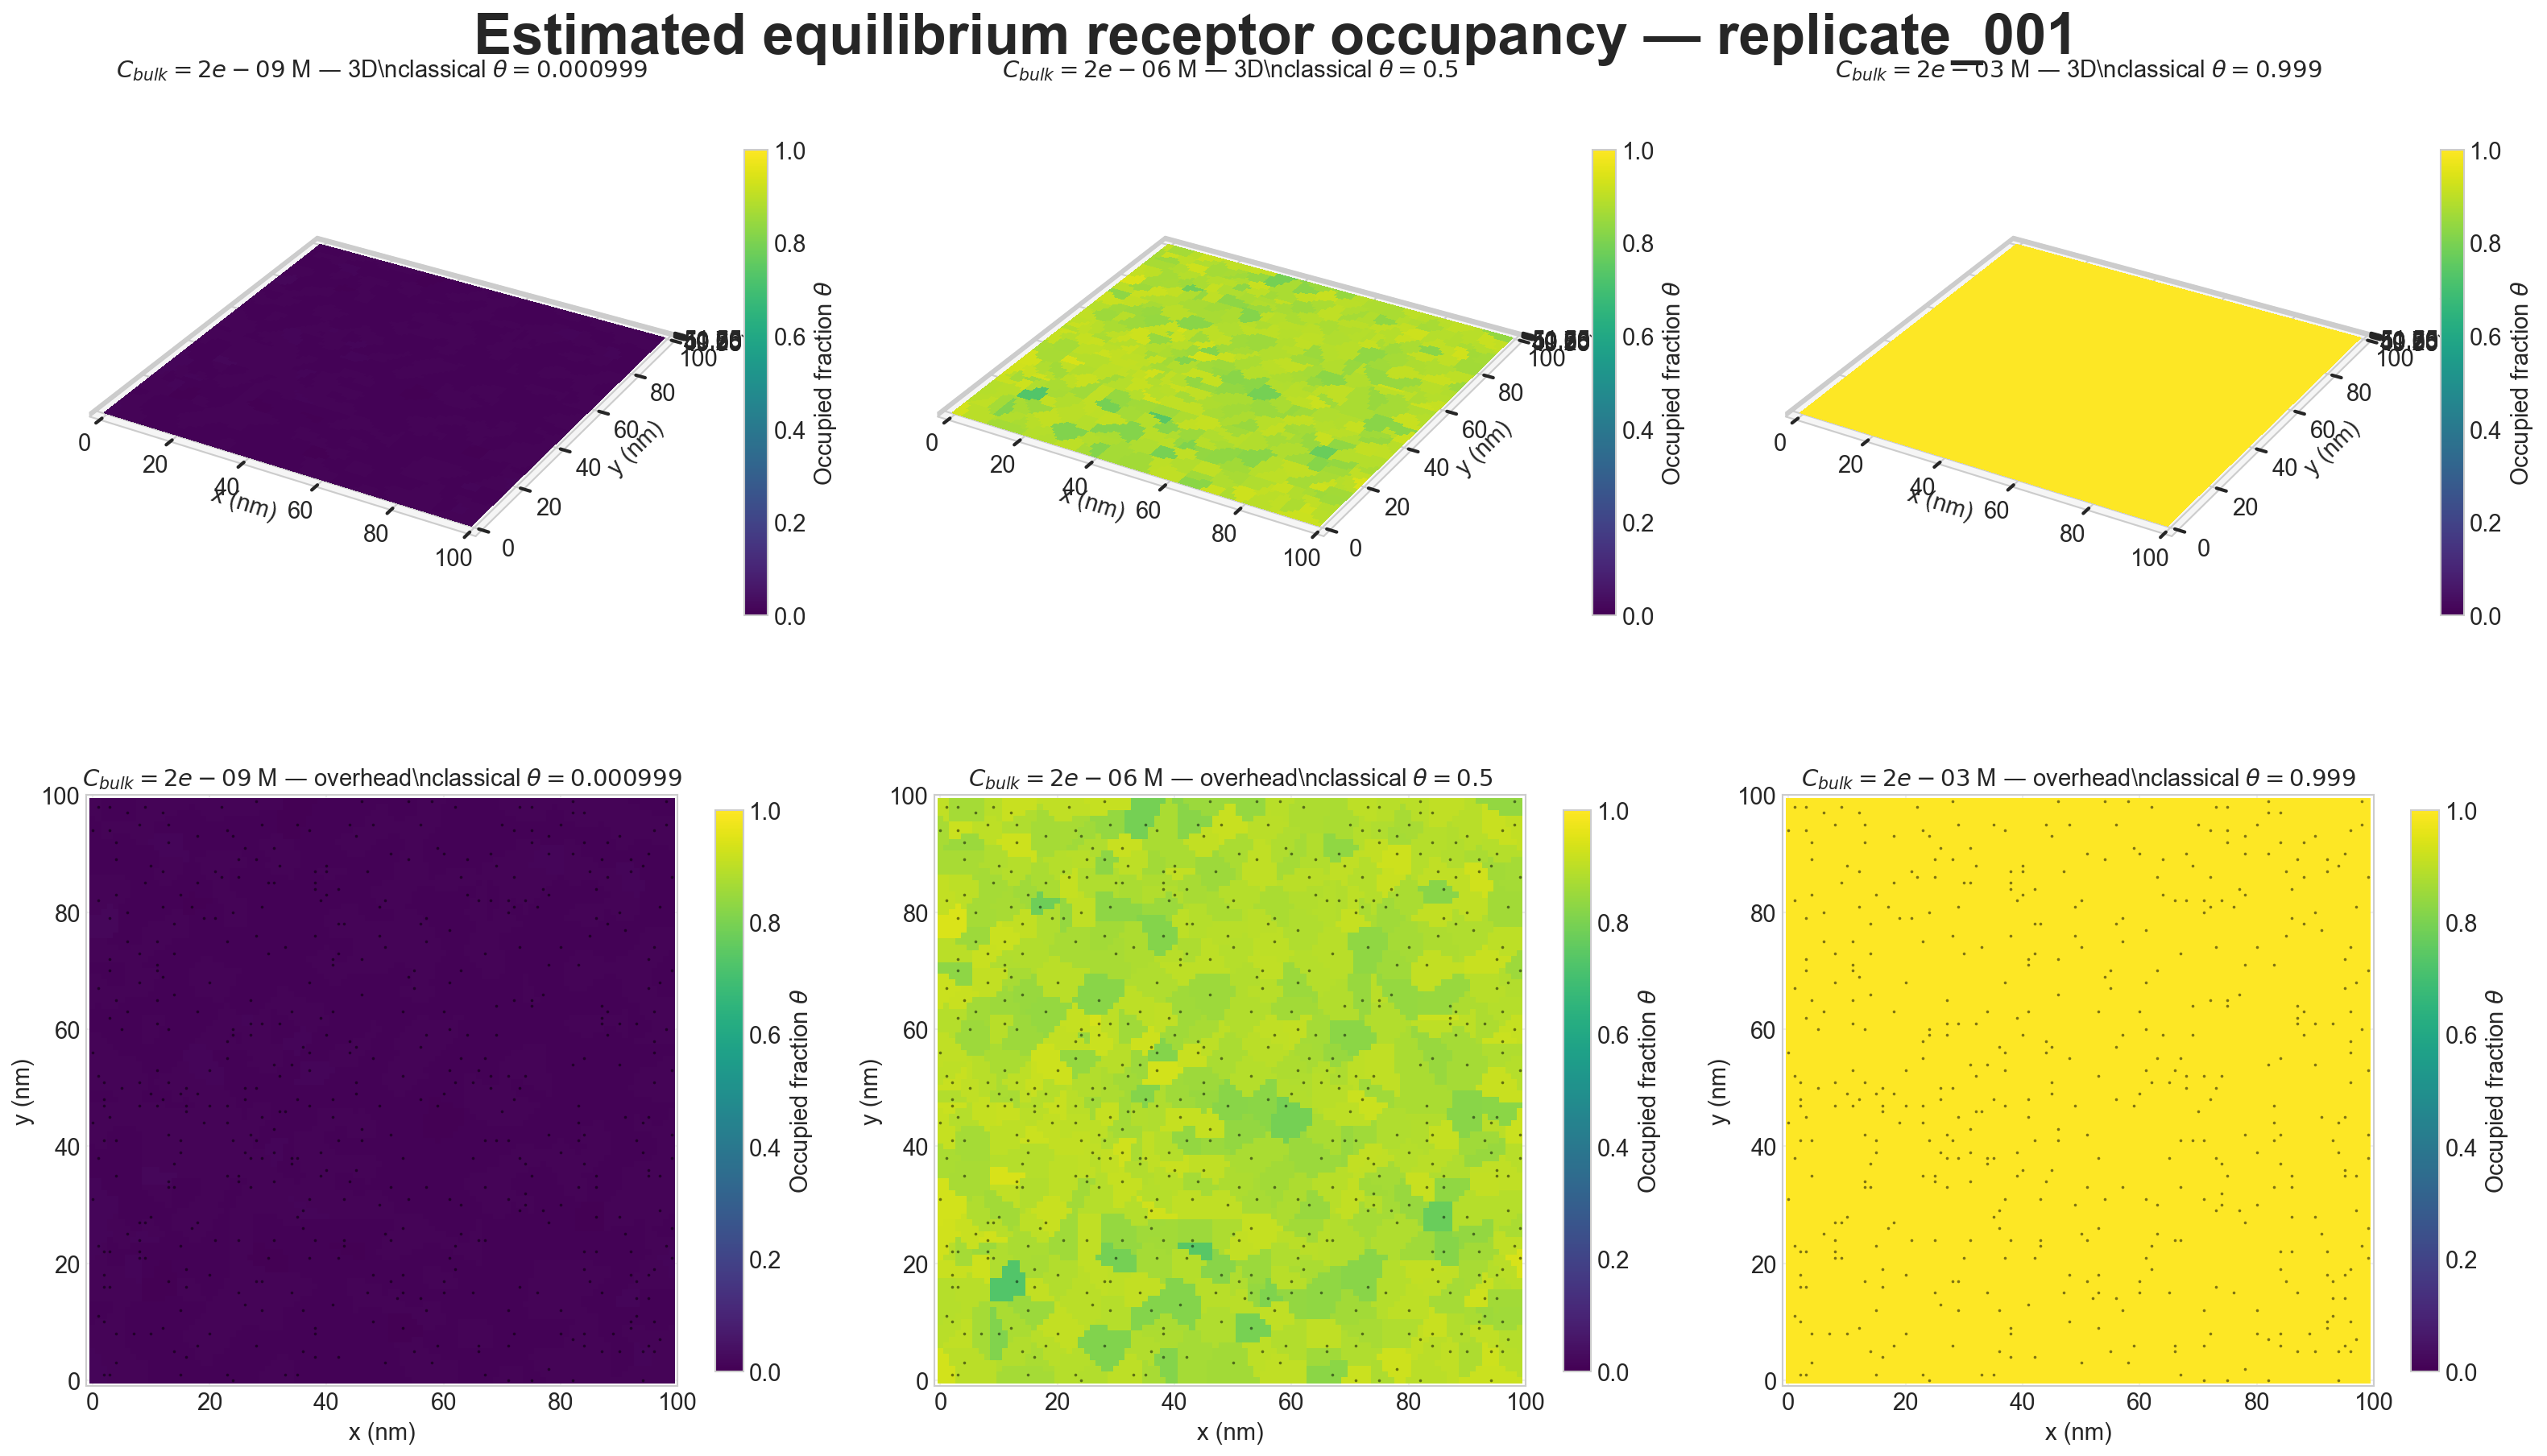

In [68]:
OCCUPANCY_MAP_CONCENTRATIONS_M = np.array([2e-9, 2e-6, 2e-3])
OCCUPANCY_CURVE_CONCENTRATIONS_M = np.logspace(-12, -7, 151)

def occupancy_from_bound_time(mean_bound_time_s, k_on_M_inv_s, concentration_M):
    bound_time = np.asarray(mean_bound_time_s, dtype=float)
    concentration = np.asarray(concentration_M, dtype=float)
    q = float(k_on_M_inv_s) * concentration * bound_time
    return np.divide(q, 1.0 + q, out=np.full(np.broadcast(q, 1.0).shape, np.nan), where=np.isfinite(q) & (q >= 0))

def classical_occupancy(k_on_M_inv_s, k_off_s, concentration_M):
    concentration = np.asarray(concentration_M, dtype=float)
    association_rate = float(k_on_M_inv_s) * concentration
    denominator = association_rate + float(k_off_s)
    return np.divide(
        association_rate, denominator,
        out=np.full(np.broadcast(association_rate, denominator).shape, np.nan),
        where=np.isfinite(denominator) & (denominator > 0),
    )

if 'mean_bound_time_s' not in archive.receptor_summary.columns:
    raise KeyError('The selected run does not contain receptor-level mean_bound_time_s.')
selected_k_on = float(archive.params.k_on_M_inv_s)
selected_k_off = float(archive.params.k_off_s)
occupancy_map_summary = archive.receptor_summary.copy()

n_map_concentrations = len(OCCUPANCY_MAP_CONCENTRATIONS_M)
fig = plt.figure(figsize=(7 * n_map_concentrations, 12), constrained_layout=True)
for column, concentration_M in enumerate(OCCUPANCY_MAP_CONCENTRATIONS_M, start=1):
    classical_theta = float(classical_occupancy(selected_k_on, selected_k_off, concentration_M))
    metric = f'equilibrium_theta_{concentration_M:.3e}_M'
    occupancy_map_summary[metric] = occupancy_from_bound_time(
        occupancy_map_summary['mean_bound_time_s'].to_numpy(float),
        selected_k_on, concentration_M,
    )
    ax_3d = fig.add_subplot(2, n_map_concentrations, column, projection='3d')
    plot_surface_metric_3d(
        archive.geometry, occupancy_map_summary, metric,
        a_m=archive.params.a_m, cmap='viridis', vmin=0, vmax=1,
        colorbar_label=r'Occupied fraction $\theta$', show_receptors=False, ax=ax_3d,
    )
    ax_3d.view_init(elev=30, azim=-60)
    ax_3d.set_title(rf'$C_{{bulk}}={concentration_M:.0e}$ M — 3D\nclassical $\theta={classical_theta:.3g}$')

    ax_xy = fig.add_subplot(2, n_map_concentrations, n_map_concentrations + column)
    plot_surface_metric_xy(
        archive.geometry, occupancy_map_summary, metric,
        a_m=archive.params.a_m, cmap='viridis', vmin=0, vmax=1,
        colorbar_label=r'Occupied fraction $\theta$', show_receptors=True,
        receptor_size=3, ax=ax_xy,
    )
    ax_xy.set_title(rf'$C_{{bulk}}={concentration_M:.0e}$ M — overhead\nclassical $\theta={classical_theta:.3g}$')
fig.suptitle(f'Estimated equilibrium receptor occupancy — {selected_directory.name}', y=1.01)
plt.show()


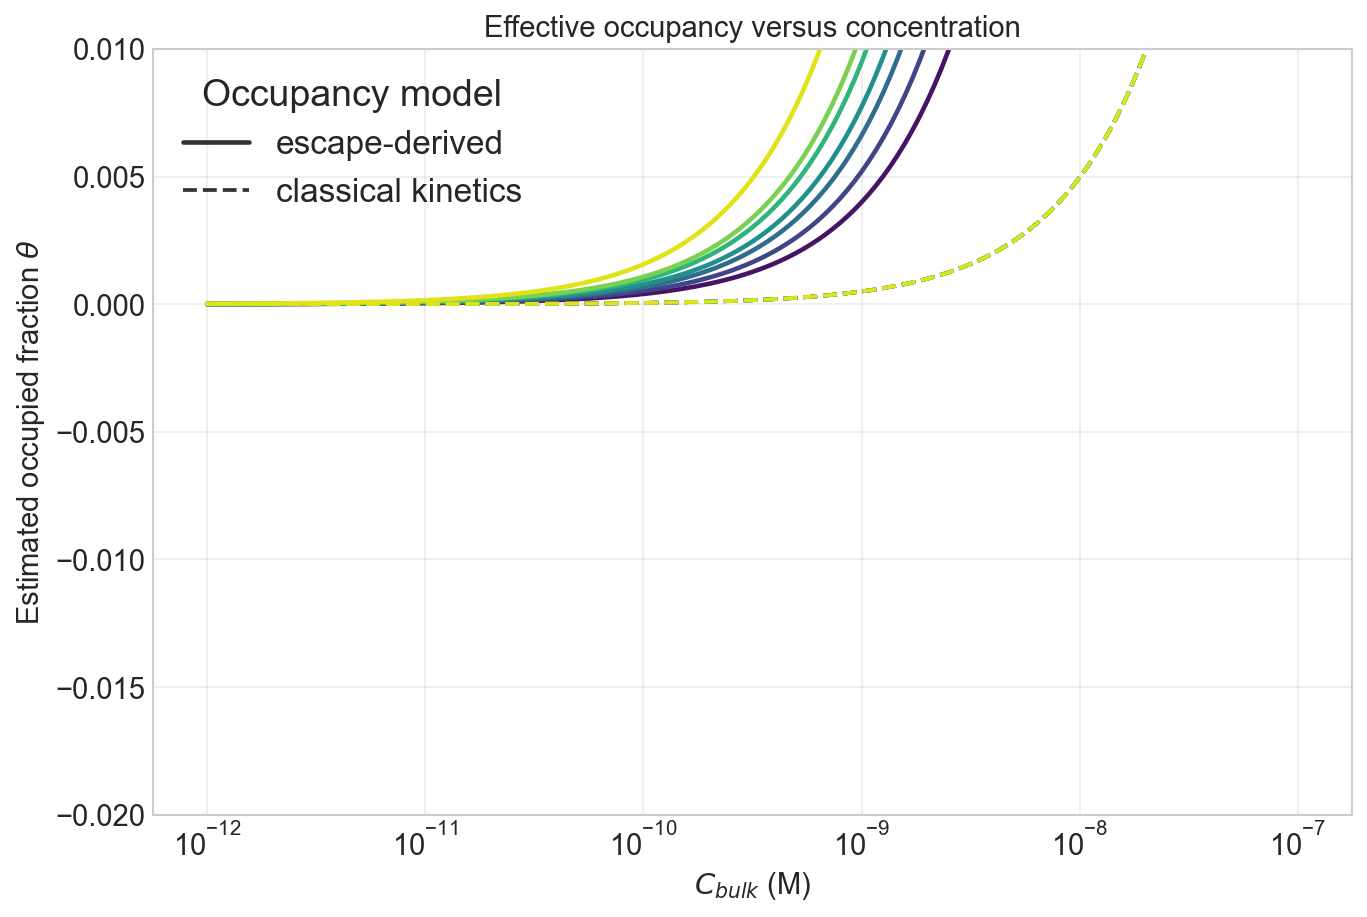

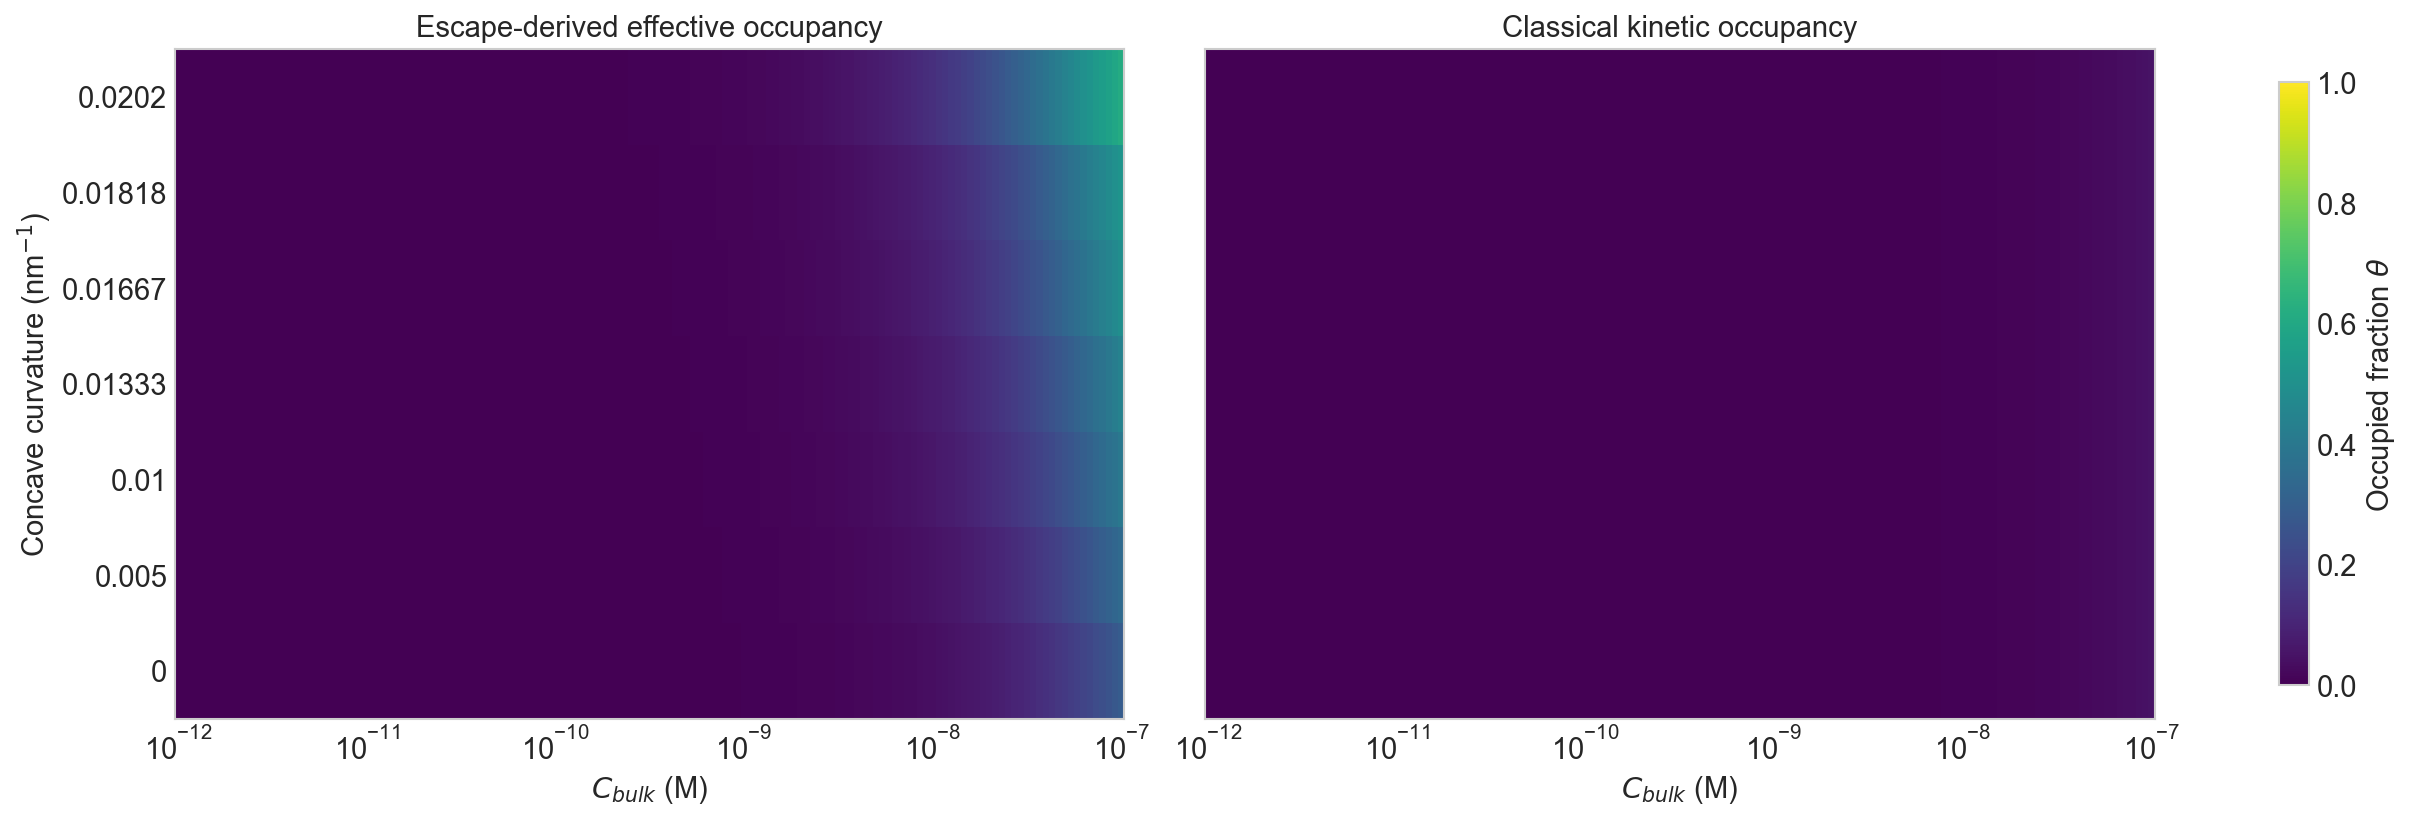

,plot_value,concentration_M,theta_mean,theta_sd,theta_sem,theta_classical_mean,theta_classical_sd,theta_classical_sem,n_replicates,mean_censoring_fraction
0,0.0,1.000000e-12,0.000004,4.089999e-08,1.829103e-08,4.999998e-07,0.0,0.0,5,0.0
1,0.0,1.079775e-12,0.000004,4.416277e-08,1.975019e-08,5.398873e-07,0.0,0.0,5,0.0
2,0.0,1.165914e-12,0.000005,4.768583e-08,2.132575e-08,5.829569e-07,0.0,0.0,5,0.0
3,0.0,1.258925e-12,0.000005,5.148993e-08,2.302700e-08,6.294623e-07,0.0,0.0,5,0.0
4,0.0,1.359356e-12,0.000005,5.559750e-08,2.486396e-08,6.796777e-07,0.0,0.0,5,0.0


In [73]:
occupancy_frames = []
for row in run_summary.itertuples(index=False):
    theta = occupancy_from_bound_time(
        row.mean_bound_time_s, row.k_on_M_inv_s, OCCUPANCY_CURVE_CONCENTRATIONS_M
    )
    theta_classical = classical_occupancy(
        row.k_on_M_inv_s, row.k_off_s, OCCUPANCY_CURVE_CONCENTRATIONS_M
    )
    occupancy_frames.append(pd.DataFrame({
        'concentration_M': OCCUPANCY_CURVE_CONCENTRATIONS_M,
        'theta': theta,
        'theta_classical': theta_classical,
        'plot_value': row.plot_value,
        'sweep_value': row.sweep_value,
        'replicate': row.replicate,
        'k_on_M_inv_s': row.k_on_M_inv_s,
        'mean_bound_time_s': row.mean_bound_time_s,
        'censoring_fraction': row.censoring_fraction,
    }))
occupancy_curves = pd.concat(occupancy_frames, ignore_index=True)
occupancy_condition_summary = (
    occupancy_curves.groupby(['plot_value', 'concentration_M'], as_index=False)
    .agg(
        theta_mean=('theta', 'mean'),
        theta_sd=('theta', 'std'),
        theta_sem=('theta', 'sem'),
        theta_classical_mean=('theta_classical', 'mean'),
        theta_classical_sd=('theta_classical', 'std'),
        theta_classical_sem=('theta_classical', 'sem'),
        n_replicates=('theta', 'count'),
        mean_censoring_fraction=('censoring_fraction', 'mean'),
    )
)
occupancy_condition_summary[[
    'theta_sd', 'theta_sem', 'theta_classical_sd', 'theta_classical_sem'
]] = (
    occupancy_condition_summary[[
        'theta_sd', 'theta_sem', 'theta_classical_sd', 'theta_classical_sem'
    ]].fillna(0.0)
)

conditions = np.sort(occupancy_condition_summary['plot_value'].dropna().unique())
colors = plt.cm.viridis(np.linspace(0.05, 0.95, max(len(conditions), 1)))
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
for color, condition in zip(colors, conditions):
    data = occupancy_condition_summary[
        occupancy_condition_summary['plot_value'] == condition
    ].sort_values('concentration_M')
    lower = np.clip(data['theta_mean'] - data['theta_sem'], 0, 1)
    upper = np.clip(data['theta_mean'] + data['theta_sem'], 0, 1)
    ax.plot(data['concentration_M'], data['theta_mean'], color=color, linewidth=2.2, label=f'{condition:.4g}')
    ax.fill_between(data['concentration_M'], lower, upper, color=color, alpha=0.18, linewidth=0)
    ax.plot(
        data['concentration_M'], data['theta_classical_mean'],
        color=color, linestyle='--', linewidth=1.8, label='_nolegend_',
    )
ax.axhline(0.5, color='0.4', linestyle=':', linewidth=1)
ax.set_xscale('log')
ax.set(
    xlabel=r'$C_{bulk}$ (M)', ylabel=r'Estimated occupied fraction $\theta$',
    ylim=(-0.02, 0.01), title='Effective occupancy versus concentration',
)
condition_legend = ax.legend(title=PLOT_PARAMETER, bbox_to_anchor=(1.02, 1), loc='upper left')
ax.add_artist(condition_legend)
style_legend = ax.legend(
    handles=[
        Line2D([0], [0], color='0.2', linewidth=2.2, label='escape-derived'),
        Line2D([0], [0], color='0.2', linewidth=1.8, linestyle='--', label='classical kinetics'),
    ],
    loc='upper left', title='Occupancy model',
)
plt.show()

occupancy_matrix = (
    occupancy_condition_summary.pivot(
        index='plot_value', columns='concentration_M', values='theta_mean'
    ).reindex(index=conditions, columns=OCCUPANCY_CURVE_CONCENTRATIONS_M)
)
classical_occupancy_matrix = (
    occupancy_condition_summary.pivot(
        index='plot_value', columns='concentration_M', values='theta_classical_mean'
    ).reindex(index=conditions, columns=OCCUPANCY_CURVE_CONCENTRATIONS_M)
)
concentration_ratio = OCCUPANCY_CURVE_CONCENTRATIONS_M[1] / OCCUPANCY_CURVE_CONCENTRATIONS_M[0]
concentration_edges = np.geomspace(
    OCCUPANCY_CURVE_CONCENTRATIONS_M[0] / np.sqrt(concentration_ratio),
    OCCUPANCY_CURVE_CONCENTRATIONS_M[-1] * np.sqrt(concentration_ratio),
    len(OCCUPANCY_CURVE_CONCENTRATIONS_M) + 1,
)
condition_edges = np.arange(len(conditions) + 1)
fig, axes = plt.subplots(
    1, 2, figsize=(16, max(3.5, 0.48 * len(conditions) + 2)),
    constrained_layout=True, sharex=True, sharey=True,
)
for ax, matrix, title in (
    (axes[0], occupancy_matrix, 'Escape-derived effective occupancy'),
    (axes[1], classical_occupancy_matrix, 'Classical kinetic occupancy'),
):
    heatmap = ax.pcolormesh(
        concentration_edges, condition_edges, matrix.to_numpy(float),
        cmap='viridis', vmin=0, vmax=1, shading='flat',
    )
    ax.set_xscale('log')
    ax.set_yticks(np.arange(len(conditions)) + 0.5, labels=[f'{value:.4g}' for value in conditions])
    ax.set(xlabel=r'$C_{bulk}$ (M)', title=title)
axes[0].set_ylabel(PLOT_PARAMETER)
fig.colorbar(heatmap, ax=axes, label=r'Occupied fraction $\theta$', shrink=0.9)
plt.show()

display(occupancy_condition_summary.head())


## 5. Parameter effects across independent replicates

Points are independent receptor-layout replicates. Lines and error bars show the mean and standard error across layouts; trajectories within one layout are not incorrectly treated as independent sweep replicates.

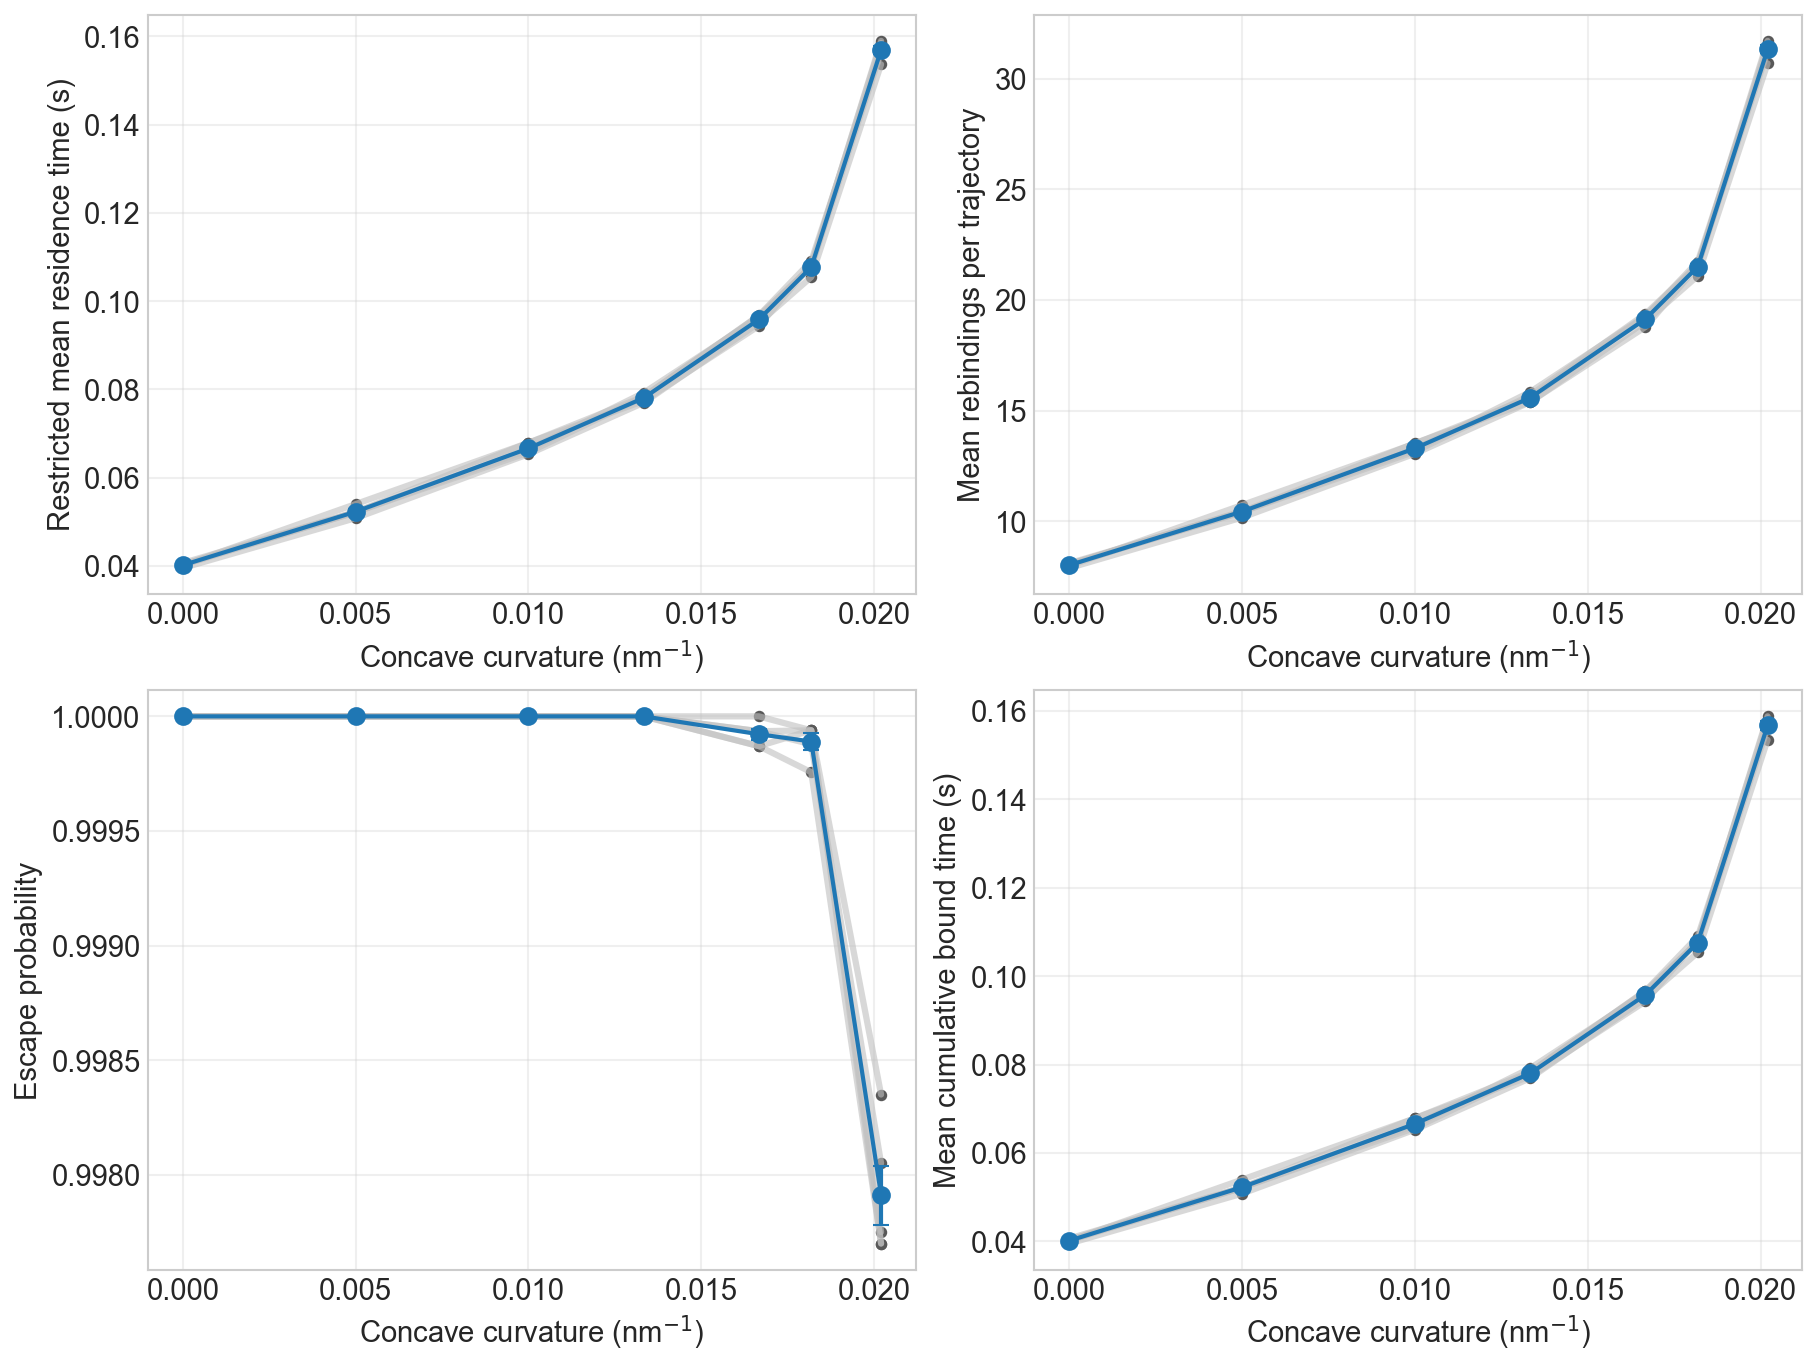

In [61]:
METRICS = [
    ("rmst_s", "Restricted mean residence time (s)"),
    ("mean_rebindings", "Mean rebindings per trajectory"),
    ("escape_probability", "Escape probability"),
    ("mean_bound_time_s", "Mean cumulative bound time (s)"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for ax, (metric, ylabel) in zip(axes.flat, METRICS):
    grouped = run_summary.groupby("plot_value")[metric]
    mean = grouped.mean()
    sem = grouped.sem().fillna(0)
    for _, replicate_data in run_summary.groupby("replicate"):
        replicate_data = replicate_data.sort_values("plot_value")
        ax.plot(replicate_data["plot_value"], replicate_data[metric], color="0.75", alpha=0.6)
        ax.scatter(replicate_data["plot_value"], replicate_data[metric], color="0.35", s=22)
    ax.errorbar(mean.index, mean, yerr=sem, color="tab:blue", marker="o", capsize=4, linewidth=2)
    ax.set(xlabel=PLOT_PARAMETER, ylabel=ylabel)
plt.show()

## 6. Residence-time and rebinding distributions

Observation-time histograms include the censored pile-up at the assay horizon. The rebinding histograms show whether changes in the mean are caused broadly or by a small high-rebinding subpopulation.

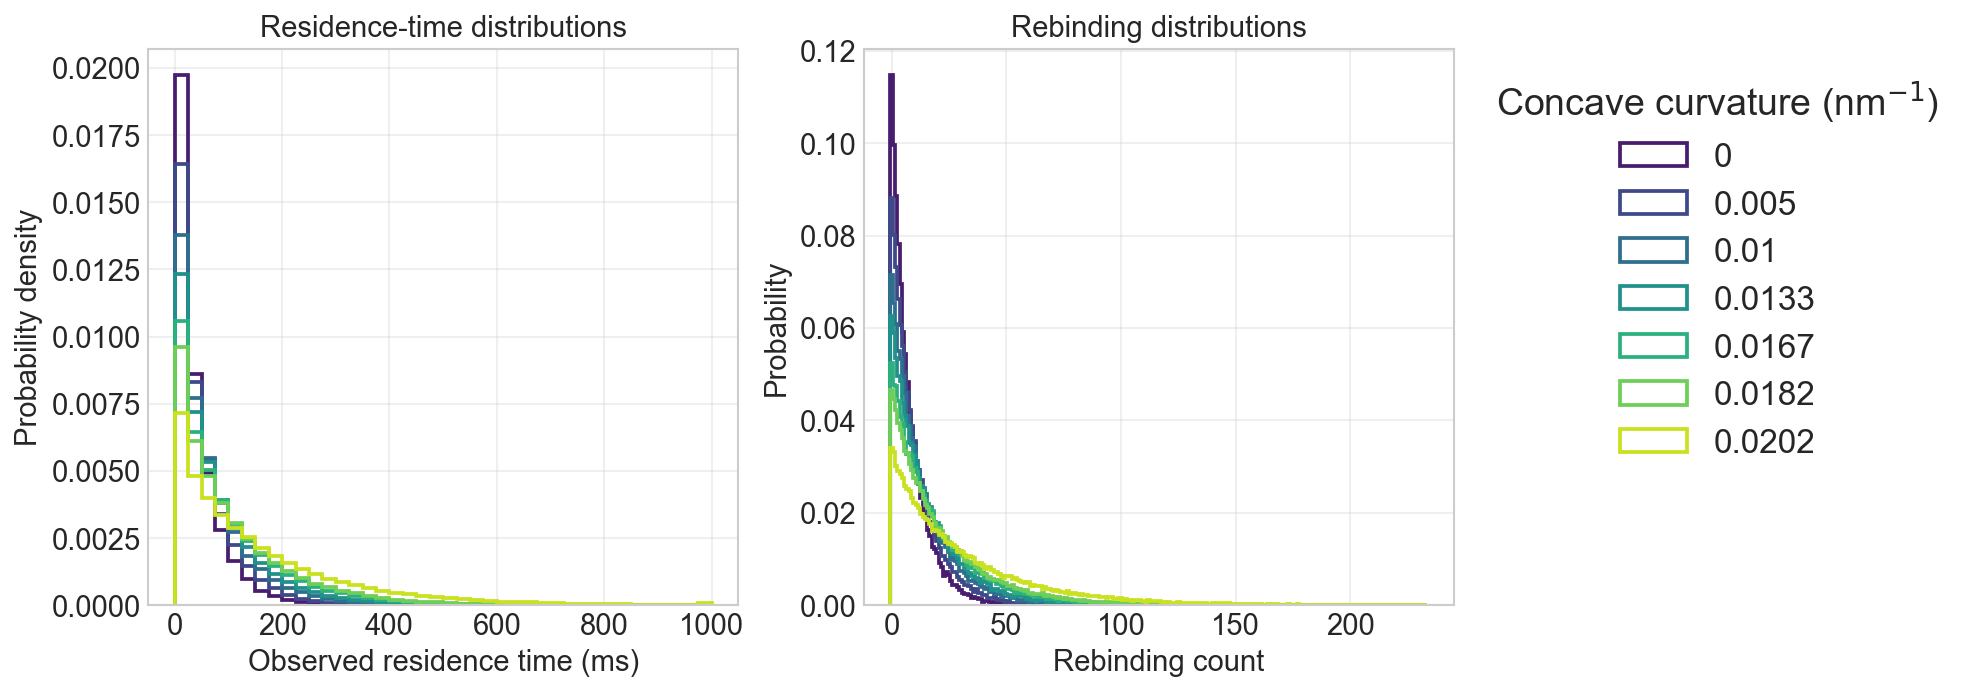

In [62]:
# Choose "linear" or "log" for the distribution x axes.
DISTRIBUTION_XSCALE = "linear"
if DISTRIBUTION_XSCALE not in {"linear", "log"}:
    raise ValueError('DISTRIBUTION_XSCALE must be either "linear" or "log".')

condition_values = np.sort(all_trajectories["plot_value"].dropna().unique())
colors = plt.cm.viridis(np.linspace(0.08, 0.92, max(len(condition_values), 1)))
residence_ms_all = all_trajectories["observation_time_s"].to_numpy(float) * 1e3
positive_residence_ms = residence_ms_all[residence_ms_all > 0]
if DISTRIBUTION_XSCALE == "log":
    if positive_residence_ms.size == 0:
        raise ValueError("Log scaling requires at least one positive residence time.")
    lower_time = positive_residence_ms.min()
    upper_time = positive_residence_ms.max()
    if np.isclose(lower_time, upper_time):
        lower_time, upper_time = lower_time / 1.1, upper_time * 1.1
    residence_bins = np.geomspace(lower_time, upper_time, 41)
else:
    lower_time, upper_time = residence_ms_all.min(), residence_ms_all.max()
    if np.isclose(lower_time, upper_time):
        padding = max(abs(lower_time) * 0.05, 1e-12)
        lower_time, upper_time = lower_time - padding, upper_time + padding
    residence_bins = np.linspace(lower_time, upper_time, 41)

rebinding_upper = max(1, int(all_trajectories["n_rebindings"].quantile(1)))
rebinding_bins = np.arange(-0.5, rebinding_upper + 1.5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for color, value in zip(colors, condition_values):
    data = all_trajectories[all_trajectories["plot_value"] == value]
    label = f"{value:.3g}"
    axes[0].hist(data["observation_time_s"] * 1e3, bins=residence_bins, density=True, histtype="step", linewidth=1.8, color=color, label=label)
    axes[1].hist(data["n_rebindings"].clip(upper=rebinding_upper), bins=rebinding_bins, density=True, histtype="step", linewidth=1.8, color=color, label=label)
if DISTRIBUTION_XSCALE == "log":
    axes[0].set_xscale("log")
    # symlog preserves the zero-rebinding bin and becomes logarithmic above 1.
    axes[1].set_xscale("symlog", linthresh=1, linscale=1)
axes[0].set(xlabel="Observed residence time (ms)", ylabel="Probability density", title="Residence-time distributions")
axes[1].set(xlabel=f"Rebinding count", ylabel="Probability", title="Rebinding distributions")
axes[1].legend(title=PLOT_PARAMETER, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## 7. Replicate-averaged condition-level Kaplan–Meier curves

A Kaplan–Meier curve is calculated independently for every receptor-layout replicate. Each condition shows the mean replicate survival curve with shading equal to ±1 standard error of the mean (SEM). Replicate-level RMST above should remain the primary inferential summary.

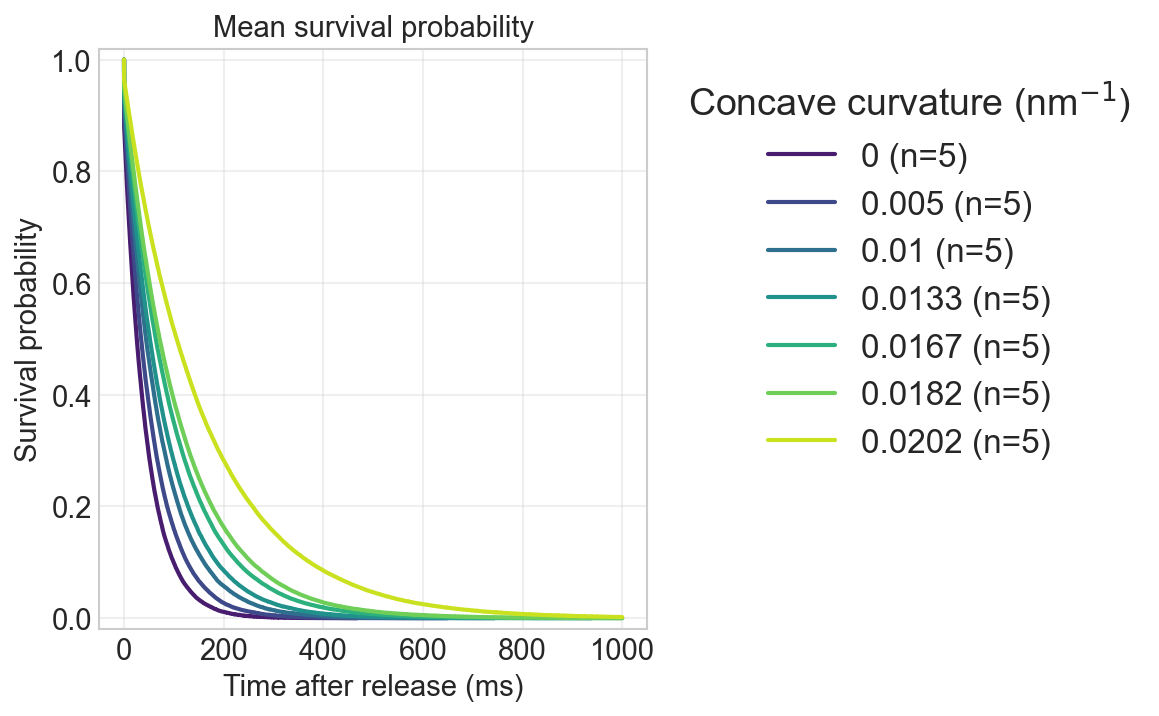

In [63]:
def kaplan_meier(times, events):
    times = np.asarray(times, dtype=float)
    events = np.asarray(events, dtype=bool)
    survival = 1.0
    rows = [(0.0, survival)]
    for time in np.unique(times[events]):
        at_risk = np.count_nonzero(times >= time)
        failures = np.count_nonzero(events & (times == time))
        survival *= 1 - failures / at_risk
        rows.append((time, survival))
    if rows[-1][0] < times.max():
        rows.append((times.max(), survival))
    return pd.DataFrame(rows, columns=["t_s", "survival_probability"])

def evaluate_step_curve(curve, time_grid):
    indices = np.searchsorted(curve["t_s"].to_numpy(float), time_grid, side="right") - 1
    indices = np.clip(indices, 0, len(curve) - 1)
    return curve["survival_probability"].to_numpy(float)[indices]

fig, ax = plt.subplots(figsize=(8, 5))
for color, value in zip(colors, condition_values):
    condition_data = all_trajectories[all_trajectories["plot_value"] == value]
    replicate_curves = []
    for _, replicate_data in condition_data.groupby("replicate", sort=True):
        replicate_curves.append(
            kaplan_meier(replicate_data["observation_time_s"], replicate_data["escaped"])
        )
    time_grid = np.unique(np.concatenate([curve["t_s"].to_numpy(float) for curve in replicate_curves]))
    replicate_survival = np.vstack([
        evaluate_step_curve(curve, time_grid) for curve in replicate_curves
    ])
    mean_survival = replicate_survival.mean(axis=0)
    if len(replicate_curves) > 1:
        sd_survival = replicate_survival.std(axis=0, ddof=1)
    else:
        sd_survival = np.zeros_like(mean_survival)
    lower = np.clip(mean_survival - sd_survival, 0.0, 1.0)
    upper = np.clip(mean_survival + sd_survival, 0.0, 1.0)
    label = f"{value:.3g} (n={len(replicate_curves)})"
    ax.step(time_grid * 1e3, mean_survival, where="post", color=color, linewidth=2, label=label)
    ax.fill_between(time_grid * 1e3, lower, upper, step="post", color=color, alpha=0.2, linewidth=0)
ax.set(xlabel="Time after release (ms)", ylabel="Survival probability", ylim=(-0.02, 1.02), title="Mean survival probability")
ax.legend(title=PLOT_PARAMETER, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 8. Relating rebinding to residence time

Residence time is decomposed into cumulative bound and free time. A strong association between rebinding and bound time supports a rebinding mechanism; a parameter effect on free time in low-rebinding trajectories is more consistent with purely geometric confinement.

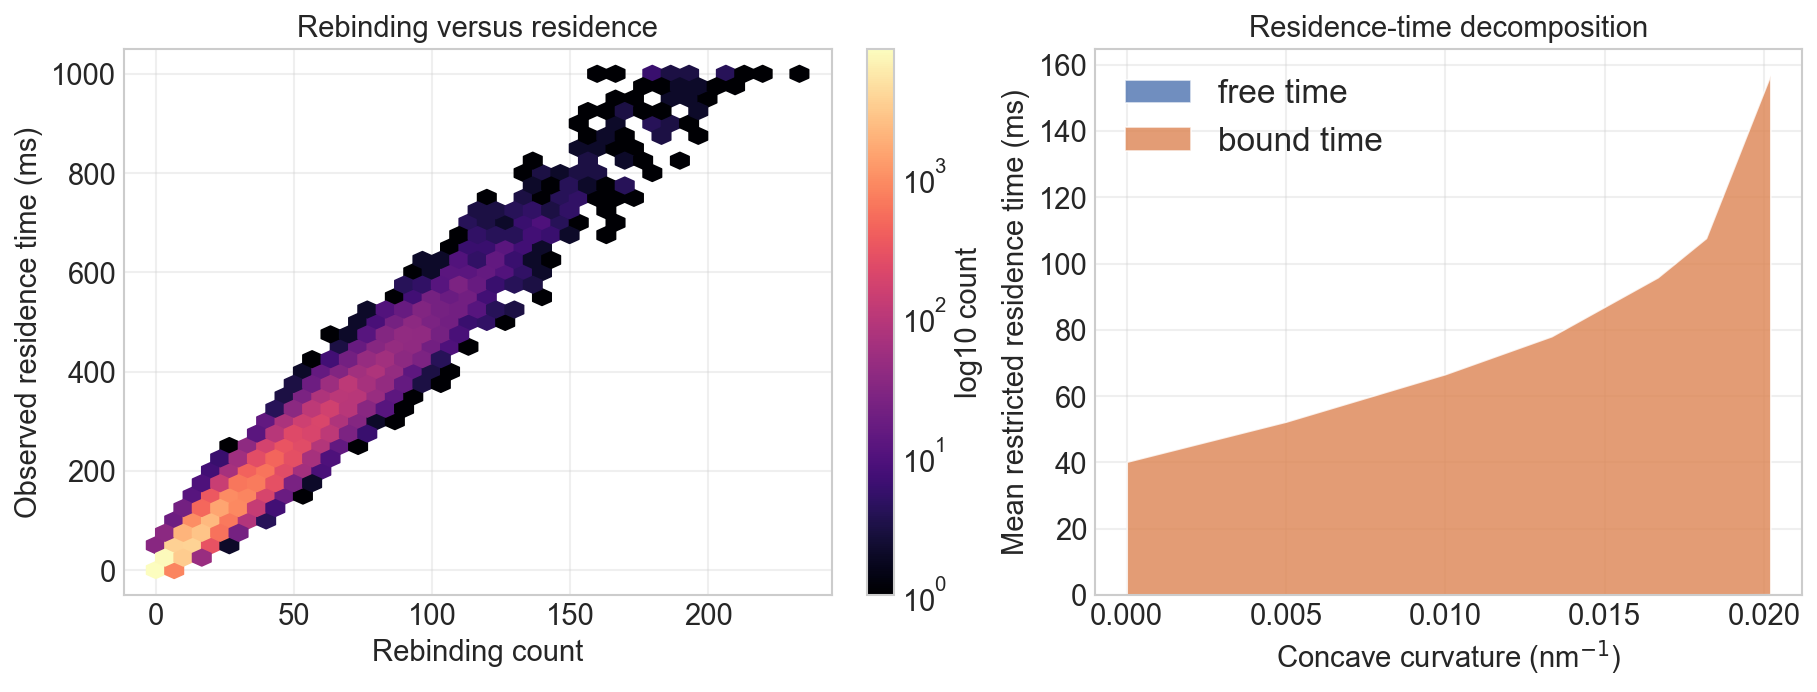

,observation_time_s,n_rebindings,total_bound_time_s,free_time_s
observation_time_s,1.000000,0.972107,0.999878,0.720956
n_rebindings,0.972107,1.000000,0.972190,0.737142
total_bound_time_s,0.999878,0.972190,1.000000,0.718266
free_time_s,0.720956,0.737142,0.718266,1.000000


In [64]:
sample = all_trajectories.sample(min(50_000, len(all_trajectories)), random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
hexbin = axes[0].hexbin(sample["n_rebindings"], sample["observation_time_s"] * 1e3, gridsize=35, mincnt=1, bins="log", cmap="magma")
fig.colorbar(hexbin, ax=axes[0], label="log10 count")
axes[0].set(xlabel="Rebinding count", ylabel="Observed residence time (ms)", title="Rebinding versus residence")

decomposition = run_summary.groupby("plot_value")[["mean_bound_time_s", "mean_free_time_s"]].mean() * 1e3
axes[1].stackplot(decomposition.index, decomposition["mean_free_time_s"], decomposition["mean_bound_time_s"], labels=["free time", "bound time"], alpha=0.8)
axes[1].set(xlabel=PLOT_PARAMETER, ylabel="Mean restricted residence time (ms)", title="Residence-time decomposition")
axes[1].legend(loc="best")
plt.show()

correlations = all_trajectories[["observation_time_s", "n_rebindings", "total_bound_time_s", "free_time_s"]].corr(method="spearman")
correlations

## 9. Residence and rebinding versus surface height

Surface height is a useful position coordinate for bowls, curved sheets, and sinusoidal fields. Condition-specific fits show whether deeper release locations exhibit longer residence or more rebinding within each geometry.

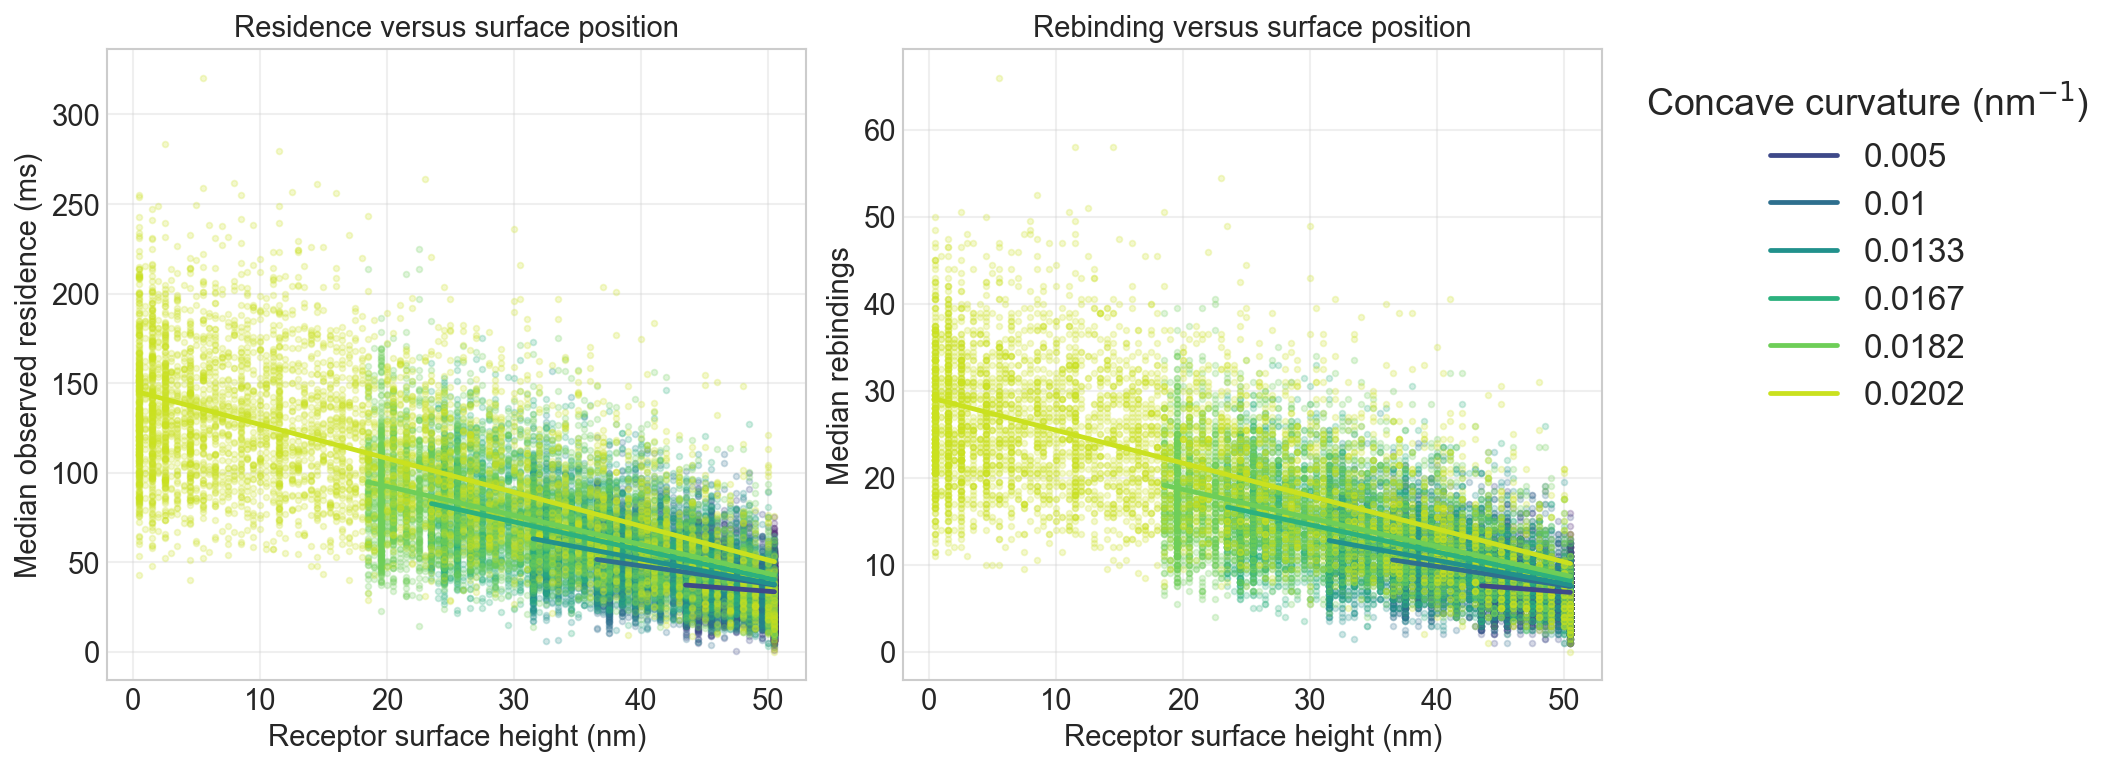

,plot_value,metric,slope_per_nm,intercept,r_squared,n_receptors
0,0.005000,median_observation_time_ms,-0.535165,60.583379,0.006302,2850
2,0.010000,median_observation_time_ms,-1.018003,88.751085,0.058333,3200
4,0.013333,median_observation_time_ms,-1.339610,105.371453,0.150483,3450
6,0.016667,median_observation_time_ms,-1.574696,119.814592,0.234103,3850
8,0.018182,median_observation_time_ms,-1.622409,124.866408,0.265352,4100
10,0.020202,median_observation_time_ms,-1.891921,145.876563,0.393224,5000
1,0.005000,median_rebindings,-0.110346,12.386421,0.007541,2850
3,0.010000,median_rebindings,-0.218489,18.531818,0.070766,3200
5,0.013333,median_rebindings,-0.269108,21.264849,0.157538,3450
7,0.016667,median_rebindings,-0.312903,23.978835,0.241228,3850


In [65]:
def linear_position_fit(data, response):
    x = data["surface_z_m"].to_numpy(float) * 1e9
    y = data[response].to_numpy(float)
    finite = np.isfinite(x) & np.isfinite(y)
    x, y = x[finite], y[finite]
    if x.size < 2 or np.unique(x).size < 2:
        return None
    slope, intercept = np.polyfit(x, y, 1)
    predicted = slope * x + intercept
    residual_ss = np.sum((y - predicted) ** 2)
    total_ss = np.sum((y - y.mean()) ** 2)
    r_squared = np.nan if total_ss == 0 else 1 - residual_ss / total_ss
    x_line = np.linspace(x.min(), x.max(), 200)
    return x_line, slope * x_line + intercept, slope, intercept, r_squared, x.size

position_conditions = np.sort(all_receptors["plot_value"].dropna().unique())
position_colors = plt.cm.viridis(
    np.linspace(0.08, 0.92, max(len(position_conditions), 1))
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
fit_rows = []
for color, value in zip(position_colors, position_conditions):
    data = all_receptors[all_receptors["plot_value"] == value]
    x_nm = data["surface_z_m"].to_numpy(float) * 1e9
    residence_ms = data["median_observation_time_s"].to_numpy(float) * 1e3
    rebindings = data["median_rebindings"].to_numpy(float)
    condition_label = f"{value:.3g}"
    axes[0].scatter(x_nm, residence_ms, color=color, s=8, alpha=0.22)
    axes[1].scatter(x_nm, rebindings, color=color, s=8, alpha=0.22)

    residence_fit = linear_position_fit(
        data.assign(median_observation_time_ms=residence_ms),
        "median_observation_time_ms",
    )
    rebinding_fit = linear_position_fit(data, "median_rebindings")
    for ax, fit, metric in (
        (axes[0], residence_fit, "median_observation_time_ms"),
        (axes[1], rebinding_fit, "median_rebindings"),
    ):
        if fit is None:
            continue
        x_line, y_line, slope, intercept, r_squared, n = fit
        ax.plot(x_line, y_line, color=color, linewidth=2.3, label=condition_label)
        fit_rows.append({
            "plot_value": value, "metric": metric, "slope_per_nm": slope,
            "intercept": intercept, "r_squared": r_squared, "n_receptors": n,
        })

axes[0].set(
    xlabel="Receptor surface height (nm)", ylabel="Median observed residence (ms)",
    title="Residence versus surface position",
)
axes[1].set(
    xlabel="Receptor surface height (nm)", ylabel="Median rebindings",
    title="Rebinding versus surface position",
)
axes[1].legend(title=PLOT_PARAMETER, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

position_fit_summary = pd.DataFrame(fit_rows).sort_values(["metric", "plot_value"])
position_fit_summary

## 10. Local curvature versus residence time and rebinding

This analysis is activated when the exported receptor summaries contain analytic curvature columns, as in the sinusoidal-field protocol. Signed mean curvature distinguishes convex peaks (negative) from concave valleys (positive). Receptors are first binned within each independent replicate; plotted points and error bars are the across-replicate mean ± SEM. Mean observation time is the receptor-level restricted mean residence time (RMST) at the assay horizon, so censored trajectories remain represented.

In [66]:
CURVATURE_COLUMN = "mean_curvature_m_inv"
N_CURVATURE_BINS = 15
CURVATURE_SCALES = {
    "mean_curvature_m_inv": (1e-9, r"Signed mean curvature (nm$^{-1}$)"),
    "abs_mean_curvature_m_inv": (1e-9, r"Absolute mean curvature (nm$^{-1}$)"),
    "principal_curvature_1_m_inv": (1e-9, r"Principal curvature 1 (nm$^{-1}$)"),
    "principal_curvature_2_m_inv": (1e-9, r"Principal curvature 2 (nm$^{-1}$)"),
    "gaussian_curvature_m_inv2": (1e-18, r"Gaussian curvature (nm$^{-2}$)"),
}
curvature_relationship_summary = pd.DataFrame()
curvature_replicate_correlations = pd.DataFrame()

required_columns = {
    CURVATURE_COLUMN, "replicate", "mean_observation_time_s", "mean_rebindings"
}
missing_columns = required_columns.difference(all_receptors.columns)
if missing_columns:
    print(
        "Curvature analysis skipped: these runs do not contain "
        f"the required receptor-summary columns: {sorted(missing_columns)}"
    )
elif CURVATURE_COLUMN not in CURVATURE_SCALES:
    raise ValueError(f"Add a display scale for {CURVATURE_COLUMN!r}.")
else:
    curvature_scale, curvature_label = CURVATURE_SCALES[CURVATURE_COLUMN]
    curvature_data = all_receptors.dropna(subset=list(required_columns)).copy()
    curvature_data["curvature_plot"] = (
        curvature_data[CURVATURE_COLUMN].astype(float) * curvature_scale
    )
    curvature_data["receptor_rmst_ms"] = (
        curvature_data["mean_observation_time_s"].astype(float) * 1e3
    )

    curvature_min = curvature_data["curvature_plot"].min()
    curvature_max = curvature_data["curvature_plot"].max()
    if np.isclose(curvature_min, curvature_max):
        raise ValueError("Curvature is constant; a within-surface relationship cannot be fitted.")
    curvature_edges = np.linspace(curvature_min, curvature_max, N_CURVATURE_BINS + 1)
    curvature_data["curvature_bin"] = pd.cut(
        curvature_data["curvature_plot"], curvature_edges, labels=False, include_lowest=True
    )

    replicate_binned = (
        curvature_data.groupby(["replicate", "curvature_bin"], observed=True)
        .agg(
            curvature_plot=("curvature_plot", "mean"),
            receptor_rmst_ms=("receptor_rmst_ms", "mean"),
            mean_rebindings=("mean_rebindings", "mean"),
            n_receptors=("location_id", "size"),
        )
        .reset_index()
    )
    summary_rows = []
    for curvature_bin, values in replicate_binned.groupby("curvature_bin", sort=True):
        row = {
            "curvature_bin": int(curvature_bin),
            "curvature_plot": values["curvature_plot"].mean(),
            "n_replicates": values["replicate"].nunique(),
            "n_receptors": values["n_receptors"].sum(),
        }
        for metric in ("receptor_rmst_ms", "mean_rebindings"):
            row[f"{metric}_mean"] = values[metric].mean()
            row[f"{metric}_sd"] = values[metric].std() if len(values) > 1 else 0.0
        summary_rows.append(row)
    curvature_relationship_summary = pd.DataFrame(summary_rows)

    correlation_rows = []
    for replicate, values in curvature_data.groupby("replicate", sort=True):
        correlation_rows.append({
            "replicate": replicate,
            "rmst_spearman_rho": values["curvature_plot"].corr(
                values["receptor_rmst_ms"], method="spearman"
            ),
            "rebindings_spearman_rho": values["curvature_plot"].corr(
                values["mean_rebindings"], method="spearman"
            ),
            "n_receptors": len(values),
        })
    curvature_replicate_correlations = pd.DataFrame(correlation_rows)

    raw_sample = curvature_data.sample(min(30_000, len(curvature_data)), random_state=1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
    plot_specs = [
        ("receptor_rmst_ms", "Mean observation time (ms)"),
        ("mean_rebindings", "Mean rebindings per trajectory"),
    ]
    for ax, (metric, ylabel) in zip(axes, plot_specs):
        ax.scatter(
            raw_sample["curvature_plot"], raw_sample[metric],
            s=5, alpha=0.05, color="0.25", rasterized=True, label="receptors",
        )
        ax.errorbar(
            curvature_relationship_summary["curvature_plot"],
            curvature_relationship_summary[f"{metric}_mean"],
            yerr=curvature_relationship_summary[f"{metric}_sd"],
            marker="o", markersize=5, linewidth=2, capsize=3,
            color="tab:blue", label="replicate mean ± SD",
        )
        if curvature_min < 0 < curvature_max:
            ax.axvline(0, color="0.4", linestyle="--", linewidth=1)
        ax.set(xlabel=curvature_label, ylabel=ylabel)
    axes[0].set_title("Curvature versus restricted residence time")
    axes[1].set_title("Curvature versus rebinding")
    axes[1].legend(loc="best")
    plt.show()

    display(curvature_relationship_summary)
    display(curvature_replicate_correlations.describe())

Curvature analysis skipped: these runs do not contain the required receptor-summary columns: ['mean_curvature_m_inv']


## 11. Optional analysis-table export

In [67]:
SAVE_ANALYSIS_TABLES = False
ANALYSIS_OUTPUT = SWEEP_ROOT / "analysis"
if SAVE_ANALYSIS_TABLES:
    ANALYSIS_OUTPUT.mkdir(parents=True, exist_ok=True)
    run_summary.to_csv(ANALYSIS_OUTPUT / "replicate_summary.csv", index=False)
    all_receptors.to_csv(ANALYSIS_OUTPUT / "receptor_summary_all_runs.csv.gz", index=False)
    occupancy_curves.to_csv(ANALYSIS_OUTPUT / "estimated_occupancy_by_replicate.csv.gz", index=False)
    occupancy_condition_summary.to_csv(ANALYSIS_OUTPUT / "estimated_occupancy_condition_summary.csv", index=False)
    if not curvature_relationship_summary.empty:
        curvature_relationship_summary.to_csv(ANALYSIS_OUTPUT / "curvature_relationship_summary.csv", index=False)
        curvature_replicate_correlations.to_csv(ANALYSIS_OUTPUT / "curvature_replicate_correlations.csv", index=False)
    print(f"Saved analysis tables to {ANALYSIS_OUTPUT.resolve()}")